# **Historical Bayesian Calibration of the Fear & Greed Estimator**

This notebook extends the existing FGIndexEstimator study with a longer reference history and a dedicated calibration experiment. The current estimator and its original analysis remain unchanged; this notebook builds a separate, reproducible frame for comparison.


## 1. Introduction and Research Question

### Purpose

The existing notebook ([Old framework](estimator.ipynb)) reconstructed the CNN Fear & Greed Index from market indicators and compared linear, Ridge, and Bayesian Ridge calibration over a shorter period. Its reported results found little improvement from regularization. 
Beyond revisiting the calibration model, this notebook introduces a longer reference series from [White Rabbit’s F&G dataset](https://github.com/whit3rabbit/fear-greed-data), on GitHub built from CNN Fear & Greed data. This lets us test whether changing both the calibration history and the regression method affects how closely the estimator tracks CNN across different market regimes. We will evaluate that question chronologically, training on earlier dates and testing on later ones

### Research question

Does calibrating the component scores with Bayesian Ridge improve out-of-sample tracking of the CNN Fear & Greed Index compared with the current equal-weight composite and an ordinary least-squares calibration?

### Why Bayesian Ridge?

The calibration is a linear model over sentiment component scores. Bayesian Ridge places a zero-centred Gaussian prior on its coefficients and estimates the coefficient and noise precisions from the data. This regularization can shrink unstable weights when component scores overlap, while the fitted model also provides posterior uncertainty for coefficients and predictive uncertainty. These properties motivate the comparison; they do not imply that Bayesian Ridge will perform better. Its uncertainty is conditional on the model assumptions and observed inputs, and the model does not by itself account for time dependence. See the [scikit-learn Bayesian Ridge documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.BayesianRidge.html).

The experiment will therefore compare models on the same features and target using chronological train/test periods. The main claim will be based on later observations that were not used to fit the model, rather than on in-sample fit alone.


## 2. Data Sources and Reproducible Loading

### Estimator inputs

The existing project pipeline loads market series and computes the raw Fear & Greed components, then maps each component to a 0–100 score with its rolling percentile transformation. The inputs include market series such as the S&P 500, VIX, TLT, RSP, and HYG, plus optional FRED series such as the high-yield spread and put/call ratio. The pipeline starts its market history in 2005 here so rolling indicators and percentile scores have time to warm up before the calibration sample begins.

### Reference target

The target is White Rabbit's daily Fear & Greed history. The primary sample uses the CNN-backed period from 2021-02-01 onward. White Rabbit also includes a pre-2021 third-party archive; it can be loaded with `source="all"` for a separate sensitivity analysis, but should not be silently treated as the same source as the CNN-backed period. See the [White Rabbit repository](https://github.com/whit3rabbit/fear-greed-data).

The loader joins the estimator frame to the reference by date and keeps the most recent estimator rows even when a target has not yet been published for that date. Its metadata records the White Rabbit source URL and fetch time. The remote CSV can change, so save the exact data snapshot used when preparing final results.


In [1]:
import pandas as pd
from IPython.display import display

import matplotlib.pyplot as plt

from load_calibration_data import load_calibration_data

plt.rcParams.update({
    "figure.facecolor": "#f5f5f5",
    "axes.facecolor":   "#ffffff",
    "axes.edgecolor":   "#cccccc",
    "grid.color":       "#dddddd",
    "text.color":       "#1f1f1f",
    "axes.labelcolor":  "#1f1f1f",
    "xtick.color":      "#666666",
    "ytick.color":      "#666666",
    "font.family":      "monospace",
})

calibration_df = load_calibration_data(
    start_date="2021-02-01",
    history_start="2005-01-01",
    source="cnn",
)


[INFO]: Using simple average for F&G estimation.


In [2]:
feature_cols_all = calibration_df.attrs["feature_columns"]
target_col = calibration_df.attrs["target_column"] # True CNN F&G score from GitHub (White Rabbit F&G data)

load_summary = pd.DataFrame(
    {
        "value": [
            calibration_df.index.min().date(),
            calibration_df.index.max().date(),
            len(calibration_df),
            len(feature_cols_all),
            int(calibration_df[target_col].notna().sum()),
            calibration_df.attrs["white_rabbit_source_url"],
            calibration_df.attrs["white_rabbit_fetched_at_utc"],
        ]
    },
    index=[
        "first estimator date",
        "last estimator date",
        "estimator rows",
        "component score columns",
        "rows with CNN target",
        "White Rabbit URL",
        "White Rabbit fetched at (UTC)",
    ],
)
display(load_summary)


,value
first estimator date,2021-02-01
last estimator date,2026-10-08
estimator rows,1484
component score columns,8
rows with CNN target,1427
White Rabbit URL,https://raw.githubusercontent.com/whit3rabbit/...
White Rabbit fetched at (UTC),2026-10-08T15:41:00.626152+00:00


## 3. Equal-Weight Baseline and Target Alignment

`FG_est_mean` is the project's uncalibrated composite: the row-wise equal-weight mean of the available component scores. It is included as a baseline, alongside the CNN reference score aligned on the same dates. The per-component scores (`score_*`) are the candidate features for calibration; raw indicators (`raw_*`) are retained for diagnostics.

The summary metrics and plot below describe the equal-weight baseline over the full period where both series overlap. They are **not** an out-of-sample model evaluation. The later validation section should evaluate fitted models on future time blocks. Rows with missing targets or incomplete component scores are excluded from the prepared calibration sample; the coverage table makes that choice visible.


In [3]:
feature_cols = [
    column
    for column in feature_cols_all
    if calibration_df[column].notna().any()
]

component_coverage = pd.DataFrame(
    {
        "non_null_rows": calibration_df[feature_cols].notna().sum(),
        "missing_percent": calibration_df[feature_cols].isna().mean().mul(100).round(1),
    }
)
display(component_coverage)

latest_estimate = calibration_df.dropna(subset=["fear_greed_score"]).tail(1)
print(f"Latest estimate date: {latest_estimate.index[0].date()}")
display(
    latest_estimate[
        ["FG_est_mean", "fear_greed_score", "sentiment", "source"]
    ]
)


,non_null_rows,missing_percent
score_momentum_spx,1484,0.0
score_strength_proxy,1484,0.0
score_breadth_rsp_spx,1484,0.0
score_safe_haven_20d,1484,0.0
score_junk_bond_mom_20d,1484,0.0
score_hy_spread,1484,0.0
score_vix_rel,1484,0.0


Latest estimate date: 2026-10-07


,FG_est_mean,fear_greed_score,sentiment,source
date,,,,
2026-10-07,52.851474,44.6,fear,cnn_endpoint


In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

baseline_sample = calibration_df.dropna(
    subset=["FG_est_mean", target_col]
).copy()
if baseline_sample.empty:
    raise ValueError("No overlapping dates are available for the baseline comparison.")

baseline_metrics = pd.DataFrame(
    [
        {
            "n": len(baseline_sample),
            "MAE": mean_absolute_error(
                baseline_sample[target_col], baseline_sample["FG_est_mean"]
            ),
            "RMSE": mean_squared_error(
                baseline_sample[target_col], baseline_sample["FG_est_mean"]
            ) ** 0.5,
            "R2": r2_score(
                baseline_sample[target_col], baseline_sample["FG_est_mean"]
            ),
        }
    ],
    index=["equal-weight FG_est_mean (descriptive, in-sample period)"],
)
display(baseline_metrics.round(3))


,n,MAE,RMSE,R2
"equal-weight FG_est_mean (descriptive, in-sample period)",1427,12.204,15.148,0.311


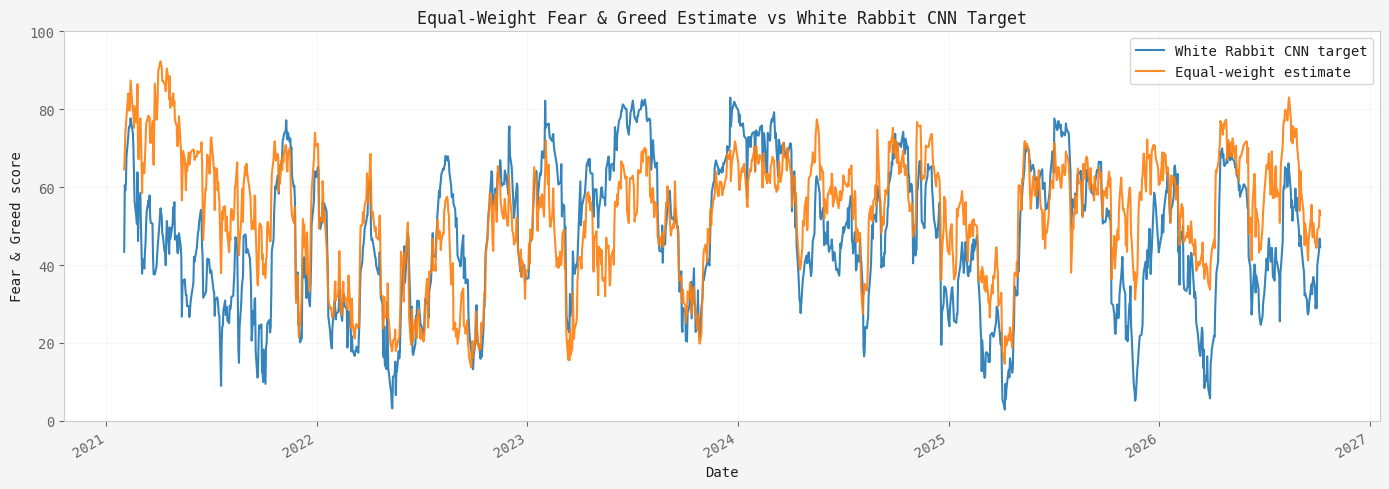

In [5]:
baseline_plot = baseline_sample[[target_col, "FG_est_mean"]].rename(
    columns={
        target_col: "White Rabbit CNN target",
        "FG_est_mean": "Equal-weight estimate",
    }
)
ax = baseline_plot.plot(figsize=(14, 5), alpha=0.9)
ax.set_title("Equal-Weight Fear & Greed Estimate vs White Rabbit CNN Target")
ax.set_xlabel("Date")
ax.set_ylabel("Fear & Greed score")
ax.set_ylim(0, 100)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [6]:
# Prepare the complete-case sample for the upcoming calibration section.
# The time-based train/test split and model fitting are intentionally defined later.
model_sample = calibration_df.dropna(
    subset=feature_cols + [target_col]
).copy()
X = model_sample[feature_cols]
y = model_sample[target_col]

print(f"Calibration rows with complete component scores and target: {len(model_sample)}")
print(f"Features: {feature_cols}")


Calibration rows with complete component scores and target: 1427
Features: ['score_momentum_spx', 'score_strength_proxy', 'score_breadth_rsp_spx', 'score_safe_haven_20d', 'score_junk_bond_mom_20d', 'score_hy_spread', 'score_vix_rel']


## 4. Bayesian Calibration Model

The calibration target is the White Rabbit CNN score, and the predictors are the component scores prepared above. The model is linear in those predictors. Bayesian Ridge uses a zero-centred Gaussian prior on the coefficients, which regularizes their size, and estimates the coefficient and residual-noise precisions from the training data. This is relevant because component scores may carry overlapping information. The model can also return a posterior predictive standard deviation; this measures uncertainty under the fitted linear-Gaussian assumptions, not all sources of market or data uncertainty.

All candidate models use the same predictors. The scaler is part of each pipeline so its means and standard deviations are learned from each training fold only. OLS is retained as a direct linear benchmark; the equal-weight composite remains the untrained baseline. For the Bayesian model, the helper below returns both the predictive mean and standard deviation. See the [Bayesian Ridge API documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.BayesianRidge.html).


In [7]:
import numpy as np
from sklearn.linear_model import BayesianRidge, LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


def make_bayesian_ridge_pipeline():
    # Scaling is fitted on each fold's training data through the Pipeline.
    return Pipeline(
        steps=[
            ("scaler", StandardScaler()),
            ("regressor", BayesianRidge()),
        ]
    )


def make_ols_pipeline():
    # OLS provides a direct linear benchmark with the same preprocessing.
    return Pipeline(
        steps=[
            ("scaler", StandardScaler()),
            ("regressor", LinearRegression()),
        ]
    )


def predict_with_uncertainty(model_name, fitted_model, X_test):
    # BayesianRidge can return the posterior predictive standard deviation.
    scaled_X_test = fitted_model.named_steps["scaler"].transform(X_test)
    regressor = fitted_model.named_steps["regressor"]

    if model_name == "Bayesian Ridge":
        prediction, prediction_std = regressor.predict(
            scaled_X_test,
            return_std=True,
        )
        return prediction, prediction_std

    return regressor.predict(scaled_X_test), None


MODEL_FACTORIES = {
    "OLS": make_ols_pipeline,
    "Bayesian Ridge": make_bayesian_ridge_pipeline,
}


## 5. Chronological Validation Design

The observations are sorted by date and split in time order. The last 252 complete observations (about one year of trading days) are reserved as a final holdout and are not used in the fold comparisons below. The earlier development period is evaluated with five expanding-window folds, each with 126 test observations (about six months). In each fold, training contains only dates before that fold's test period. This follows the time-series validation principle described in the [scikit-learn cross-validation guide](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-of-time-series-data).

The equal-weight baseline, OLS, and Bayesian Ridge are scored on the same test dates with MAE, RMSE, and R². For Bayesian Ridge, 95% predictive-interval coverage is also recorded as a diagnostic. These folds support model comparison; use the reserved final holdout only after choosing the specification. The exact calendar length of each fold can vary slightly around holidays or missing observations.


In [8]:
from sklearn.model_selection import TimeSeriesSplit

# Keep only dates with all selected predictors, the reference target, and the
# equal-weight estimate needed for a fair baseline comparison.
validation_sample = (
    calibration_df.dropna(
        subset=feature_cols + [target_col, "FG_est_mean"]
    )
    .sort_index()
    .copy()
)

N_SPLITS = 5
TEST_SIZE = 126  # Approximately six months of business-day observations.
FINAL_HOLDOUT_SIZE = 252  # Approximately one final year, reserved for later.
MIN_TRAIN_SIZE = 252  # Require at least one year in the first training fold.

if len(validation_sample) <= FINAL_HOLDOUT_SIZE:
    raise ValueError(
        "There are not enough complete observations to reserve the final holdout."
    )

development_sample = validation_sample.iloc[:-FINAL_HOLDOUT_SIZE].copy()
final_holdout = validation_sample.iloc[-FINAL_HOLDOUT_SIZE:].copy()
first_train_size = len(development_sample) - N_SPLITS * TEST_SIZE
if first_train_size < MIN_TRAIN_SIZE:
    raise ValueError(
        "The development sample is too short for the configured folds. "
        "Reduce N_SPLITS or TEST_SIZE, or collect more history."
    )

X_development = development_sample[feature_cols]
y_development = development_sample[target_col]
time_splitter = TimeSeriesSplit(
    n_splits=N_SPLITS,
    test_size=TEST_SIZE,
)

print(f"Complete observations: {len(validation_sample)}")
print(f"Development observations: {len(development_sample)}")
print(f"Reserved final holdout observations: {len(final_holdout)}")
print(f"Initial training observations per first fold: {first_train_size}")


Complete observations: 1427
Development observations: 1175
Reserved final holdout observations: 252
Initial training observations per first fold: 545


In [9]:
from matplotlib.lines import Line2D


def plot_time_series_folds(splitter, development_frame):
    """Plot the expanding training and test date ranges for each CV fold."""
    fold_indices = list(splitter.split(development_frame))
    fig, ax = plt.subplots(figsize=(13, 0.8 * len(fold_indices)))
    train_color = "#4776B4"
    test_color = "#E07A3F"

    for fold_number, (train_idx, test_idx) in enumerate(fold_indices, start=1):
        train_dates = development_frame.index[train_idx]
        test_dates = development_frame.index[test_idx]

        ax.plot(
            [train_dates[0], train_dates[-1]],
            [fold_number, fold_number],
            color=train_color,
            linewidth=15,
            solid_capstyle="butt",
        )
        ax.plot(
            [test_dates[0], test_dates[-1]],
            [fold_number, fold_number],
            color=test_color,
            linewidth=15,
            solid_capstyle="butt",
        )

    ax.set_yticks(
        range(1, len(fold_indices) + 1),
        labels=[f"Fold {fold_number}" for fold_number in range(1, len(fold_indices) + 1)],
    )
    ax.set_ylim(len(fold_indices) + 0.5, 0.5)
    ax.set_title("Expanding-Window Cross-Validation Folds")
    ax.set_xlabel("Date")
    ax.set_ylabel("Validation fold")
    ax.grid(axis="x", alpha=0.25)
    ax.legend(
        handles=[
            Line2D([0], [0], color=train_color, linewidth=7, label="Training window"),
            Line2D([0], [0], color=test_color, linewidth=7, label="Test window"),
        ],
        loc="upper left",
        edgecolor="none",
        facecolor="none",
        bbox_to_anchor=(1.01, 1),
    )
    fig.tight_layout()
    plt.show()


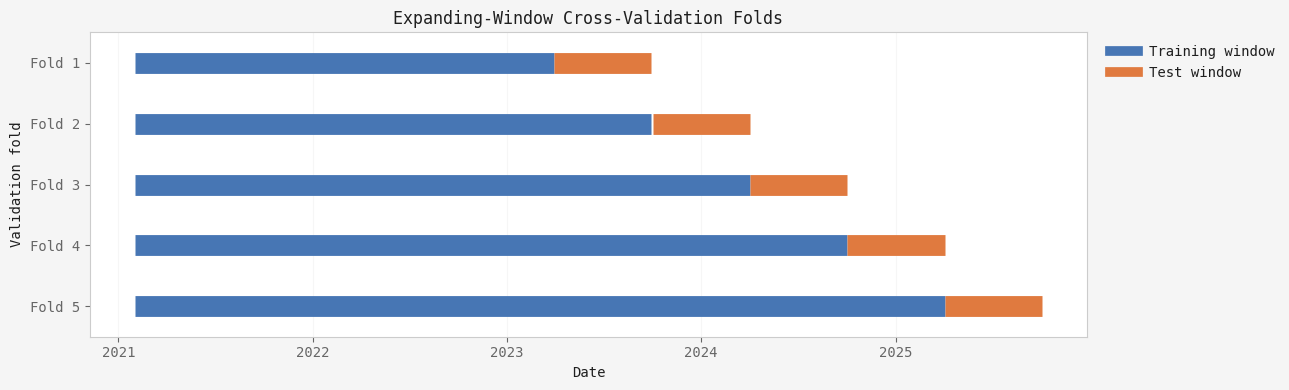

,fold,model,train_start,train_end,test_start,test_end,n_test,MAE,RMSE,R2,coverage_95
0,1,Equal-weight,2021-02-01,2023-03-30,2023-03-31,2023-09-29,126,12.499,14.306,-0.053,NaN
1,1,OLS,2021-02-01,2023-03-30,2023-03-31,2023-09-29,126,12.657,13.927,0.002,NaN
2,1,Bayesian Ridge,2021-02-01,2023-03-30,2023-03-31,2023-09-29,126,12.427,13.715,0.032,0.905
3,2,Equal-weight,2021-02-01,2023-09-29,2023-10-02,2024-04-02,126,6.261,7.500,0.830,NaN
4,2,OLS,2021-02-01,2023-09-29,2023-10-02,2024-04-02,126,11.764,14.966,0.321,NaN
5,2,Bayesian Ridge,2021-02-01,2023-09-29,2023-10-02,2024-04-02,126,12.063,15.079,0.311,0.778
6,3,Equal-weight,2021-02-01,2024-04-02,2024-04-03,2024-10-01,126,10.386,11.818,-0.141,NaN
7,3,OLS,2021-02-01,2024-04-02,2024-04-03,2024-10-01,126,6.589,8.148,0.457,NaN
8,3,Bayesian Ridge,2021-02-01,2024-04-02,2024-04-03,2024-10-01,126,6.564,8.116,0.462,0.984
9,4,Equal-weight,2021-02-01,2024-10-01,2024-10-02,2025-04-03,126,11.160,12.664,0.500,NaN


In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

fold_metric_rows = []
prediction_frames = []

for fold_number, (train_idx, test_idx) in enumerate(
    time_splitter.split(X_development),
    start=1,
):
    train_frame = development_sample.iloc[train_idx]
    test_frame = development_sample.iloc[test_idx]
    X_train = train_frame[feature_cols]
    y_train = train_frame[target_col]
    X_test = test_frame[feature_cols]
    y_test = test_frame[target_col].to_numpy()

    # The baseline uses the existing equal-weight score without fitting.
    fold_predictions = {
        "Equal-weight": (
            test_frame["FG_est_mean"].to_numpy(),
            None,
        )
    }

    # Fit each regression pipeline from scratch on this fold's past data.
    for model_name, model_factory in MODEL_FACTORIES.items():
        fitted_model = model_factory()
        fitted_model.fit(X_train, y_train)
        prediction, prediction_std = predict_with_uncertainty(
            model_name,
            fitted_model,
            X_test,
        )
        fold_predictions[model_name] = (prediction, prediction_std)

    for model_name, (prediction, prediction_std) in fold_predictions.items():
        if prediction_std is None:
            coverage_95 = np.nan
            stored_std = np.full(len(prediction), np.nan)
        else:
            lower_95 = prediction - 1.96 * prediction_std
            upper_95 = prediction + 1.96 * prediction_std
            coverage_95 = np.mean((y_test >= lower_95) & (y_test <= upper_95))
            stored_std = prediction_std

        fold_metric_rows.append(
            {
                "fold": fold_number,
                "model": model_name,
                "train_start": train_frame.index[0].date(),
                "train_end": train_frame.index[-1].date(),
                "test_start": test_frame.index[0].date(),
                "test_end": test_frame.index[-1].date(),
                "n_test": len(test_frame),
                "MAE": mean_absolute_error(y_test, prediction),
                "RMSE": mean_squared_error(y_test, prediction) ** 0.5,
                "R2": r2_score(y_test, prediction),
                "coverage_95": coverage_95,
            }
        )

        prediction_frame = pd.DataFrame(
            {
                "fold": fold_number,
                "model": model_name,
                "actual": y_test,
                "prediction": prediction,
                "prediction_std": stored_std,
            },
            index=test_frame.index,
        )
        prediction_frame.index.name = "date"
        prediction_frames.append(prediction_frame.reset_index())

fold_metrics = pd.DataFrame(fold_metric_rows)
cv_predictions = pd.concat(prediction_frames, ignore_index=True)

# Review per-fold metrics before using the reserved final holdout.
plot_time_series_folds(time_splitter, X_development)

display(fold_metrics.round(3))


## 6. Results and Comparison with Baselines



### Development-period comparison

The folds share the same test dates, so compare each metric across the same observations. The predeclared ranking criterion is the mean of the fold RMSE values. That produces a criterion-specific candidate, not a universal winner: MAE and R² can rank models differently, and fold-to-fold variation matters. In the saved run, the equal-weight baseline had the lowest mean fold RMSE, while Bayesian Ridge had a higher mean R²; this is not an arithmetic error, but it does show why the metric must be stated explicitly.

The final row-based holdout below evaluates **all three linear candidates** on the same dates, rather than evaluating only the model selected by mean RMSE. Section 8 separately compares OLS, Bayesian Ridge, GRU, and equal weights on the latest calendar-year CNN window. That latest-year period has now been inspected, so treat it as a historical comparison used for model choice, not as a fresh untouched test.


In [11]:
cv_summary = (
    fold_metrics.groupby("model")
    .agg(
        mean_MAE=("MAE", "mean"),
        sd_MAE=("MAE", "std"),
        mean_RMSE=("RMSE", "mean"),
        sd_RMSE=("RMSE", "std"),
        mean_R2=("R2", "mean"),
        mean_coverage_95=("coverage_95", "mean"),
    )
)

# Show the leader for each metric: a ranking on one metric is not a universal winner.
metric_leaders = pd.Series(
    {
        "lowest mean MAE": cv_summary["mean_MAE"].idxmin(),
        "lowest mean RMSE (predeclared selection criterion)": cv_summary["mean_RMSE"].idxmin(),
        "highest mean R2": cv_summary["mean_R2"].idxmax(),
    },
    name="model",
)
display(cv_summary.sort_values("mean_RMSE").round(3))
display(metric_leaders.to_frame())

selected_model = cv_summary["mean_RMSE"].idxmin()
print(f"Candidate under the predeclared mean-RMSE rule: {selected_model}")


,mean_MAE,sd_MAE,mean_RMSE,sd_RMSE,mean_R2,mean_coverage_95
model,,,,,,
Equal-weight,9.286,2.924,10.741,3.127,0.393,NaN
Bayesian Ridge,9.649,2.700,11.541,2.937,0.426,0.914
OLS,9.728,2.690,11.666,2.929,0.415,NaN


,model
lowest mean MAE,Equal-weight
lowest mean RMSE (predeclared selection criterion),Equal-weight
highest mean R2,Bayesian Ridge


Candidate under the predeclared mean-RMSE rule: Equal-weight


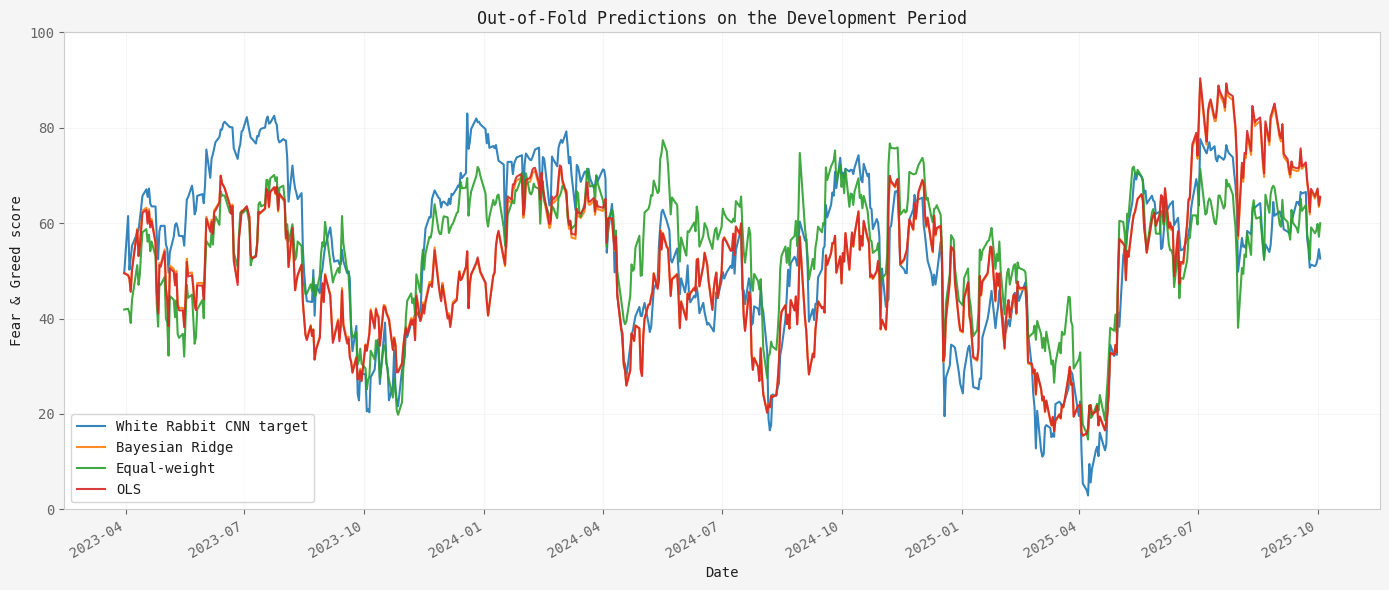

In [12]:
# Show out-of-fold predictions only; each date was predicted by a model trained
# on earlier observations. The reserved final holdout is not included here.
oof_actual = (
    cv_predictions.drop_duplicates(subset="date")
    .set_index("date")["actual"]
    .rename("White Rabbit CNN target")
)
oof_model_predictions = cv_predictions.pivot(
    index="date",
    columns="model",
    values="prediction",
)

oof_plot_data = pd.concat([oof_actual, oof_model_predictions], axis=1)

ax = oof_plot_data.plot(figsize=(14, 6), alpha=0.9)
ax.set_title("Out-of-Fold Predictions on the Development Period")
ax.set_xlabel("Date")
ax.set_ylabel("Fear & Greed score")
ax.set_ylim(0, 100)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


,n,MAE,RMSE,R2,coverage_95
model,,,,,
Equal-weight,252,16.330,18.332,-0.303,NaN
OLS,252,10.686,12.602,0.384,NaN
Bayesian Ridge,252,10.654,12.579,0.386,0.853


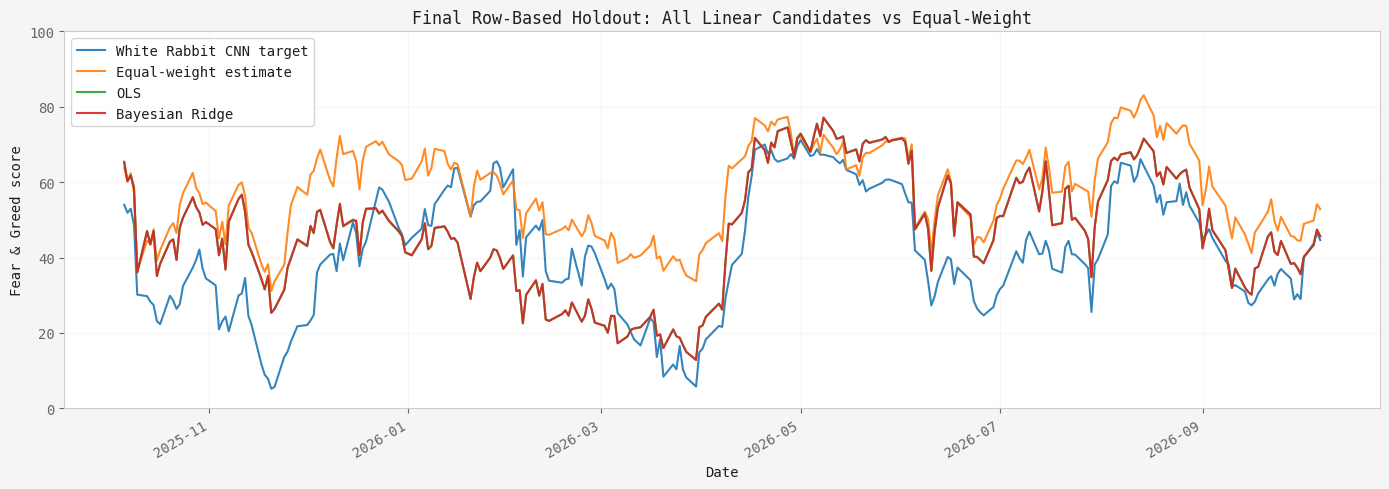

In [13]:
# Evaluate every linear candidate on the same reserved final holdout.
holdout_actual = final_holdout[target_col].to_numpy()
holdout_prediction_map = {
    "Equal-weight": final_holdout["FG_est_mean"].to_numpy(),
}
holdout_std_map = {"Equal-weight": None}

for model_name, model_factory in MODEL_FACTORIES.items():
    final_candidate = model_factory()
    final_candidate.fit(
        development_sample[feature_cols],
        development_sample[target_col],
    )
    prediction, prediction_std = predict_with_uncertainty(
        model_name,
        final_candidate,
        final_holdout[feature_cols],
    )
    holdout_prediction_map[model_name] = prediction
    holdout_std_map[model_name] = prediction_std

holdout_metric_rows = []
for model_name, prediction in holdout_prediction_map.items():
    prediction_std = holdout_std_map[model_name]
    if prediction_std is None:
        coverage_95 = np.nan
    else:
        lower_95 = prediction - 1.96 * prediction_std
        upper_95 = prediction + 1.96 * prediction_std
        coverage_95 = np.mean(
            (holdout_actual >= lower_95) & (holdout_actual <= upper_95)
        )

    holdout_metric_rows.append(
        {
            "model": model_name,
            "n": len(holdout_actual),
            "MAE": mean_absolute_error(holdout_actual, prediction),
            "RMSE": mean_squared_error(holdout_actual, prediction) ** 0.5,
            "R2": r2_score(holdout_actual, prediction),
            "coverage_95": coverage_95,
        }
    )

holdout_results = pd.DataFrame(holdout_metric_rows).set_index("model")
display(holdout_results.round(3))

holdout_plot_data = final_holdout[[target_col, "FG_est_mean"]].rename(
    columns={
        target_col: "White Rabbit CNN target",
        "FG_est_mean": "Equal-weight estimate",
    }
).copy()
for model_name in MODEL_FACTORIES:
    holdout_plot_data[model_name] = holdout_prediction_map[model_name]

ax = holdout_plot_data.plot(figsize=(14, 5), alpha=0.9)
ax.set_title("Final Row-Based Holdout: All Linear Candidates vs Equal-Weight")
ax.set_xlabel("Date")
ax.set_ylabel("Fear & Greed score")
ax.set_ylim(0, 100)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 7. Robustness Checks and Limitations



### Coefficient stability across time folds

A calibration that tracks well but changes its component weights sharply from fold to fold may be sensitive to the market period. The next cell refits Bayesian Ridge on each development fold's training window and compares standardized coefficients. Because each fold fits its own scaler, these coefficients describe the effect of a one-standard-deviation change in a component within that training window; inspect both their direction and variation.


In [14]:
coefficient_rows = []

for fold_number, (train_idx, _) in enumerate(
    time_splitter.split(X_development),
    start=1,
):
    train_frame = development_sample.iloc[train_idx]
    fold_model = make_bayesian_ridge_pipeline()
    fold_model.fit(
        train_frame[feature_cols],
        train_frame[target_col],
    )
    standardized_coefficients = fold_model.named_steps["regressor"].coef_

    for feature_name, coefficient in zip(
        feature_cols,
        standardized_coefficients,
    ):
        coefficient_rows.append(
            {
                "fold": fold_number,
                "component": feature_name,
                "standardized_coefficient": coefficient,
            }
        )

coefficient_by_fold = pd.DataFrame(coefficient_rows)
coefficient_stability = (
    coefficient_by_fold.groupby("component")["standardized_coefficient"]
    .agg(mean="mean", std="std", minimum="min", maximum="max")
    .sort_values("mean")
)
display(coefficient_stability.round(3))


,mean,std,minimum,maximum
component,,,,
score_strength_proxy,-17.291,2.964,-21.894,-14.505
score_breadth_rsp_spx,-1.137,0.791,-2.197,-0.351
score_hy_spread,-1.062,1.492,-3.104,1.013
score_vix_rel,3.018,0.484,2.264,3.469
score_junk_bond_mom_20d,3.282,1.152,1.905,4.441
score_safe_haven_20d,5.250,0.766,4.524,6.343
score_momentum_spx,23.444,1.705,21.197,25.590


### Source sensitivity and interpretation limits

The primary calibration deliberately uses the CNN-backed White Rabbit period. Its earlier archive has a different provenance, so any source-sensitivity analysis should report those observations separately and should not silently pool them with CNN-backed scores. The optional diagnostic below loads both source eras and summarizes their coverage and score distributions; it is disabled by default because it triggers another data load.

Other limitations to report:

- Daily scores and market features are serially dependent, so the number of observations overstates the amount of independent information.
- Bayesian Ridge remains a linear, Gaussian model. It does not model changing coefficients, regime transitions, or nonlinear interactions by itself.
- Its predictive uncertainty is conditional on the fitted model and inputs; it excludes uncertainty from data revisions, source differences, and model choice.
- Linear predictions are not mathematically constrained to 0–100. Evaluate the raw predictions as reported; if a bounded version is later used operationally, report its metrics separately.
- Same-date market features make this a historical replication exercise. A future forecast must handle inputs that will not be known at the forecast origin.
- The live White Rabbit CSV may change. Preserve the data snapshot, fetch time, and model settings used for final reported results.


In [15]:
# Optional source-provenance diagnostic. Set to True only when you want to
# reload the wider White Rabbit history, including its pre-2021 third-party archive.
RUN_ARCHIVE_SOURCE_DIAGNOSTIC = True

if RUN_ARCHIVE_SOURCE_DIAGNOSTIC:
    archive_sensitivity_df = load_calibration_data(
        start_date="2011-01-03",
        history_start="2005-01-01",
        source="all",
    )
    source_summary = (
        archive_sensitivity_df.dropna(subset=["fear_greed_score"])
        .groupby("source")["fear_greed_score"]
        .agg(
            observations="count",
            mean="mean",
            std="std",
            minimum="min",
            maximum="max",
        )
    )
    display(source_summary.round(2))


[INFO]: Using simple average for F&G estimation.


,observations,mean,std,minimum,maximum
source,,,,,
cnn_endpoint,1427,47.23,18.25,2.9,82.97
third_party_archive,2514,49.71,22.28,0.0,97.00


### Does Adding Pre-2021 Archive History Change Calibration?

White Rabbit's README describes its pre-2021 segment (2011-01-03 to 2021-01-29) as a frozen archive derived from a combined Hackingthemarkets and Openstockalert file. Those older scores are integers, and their labels are assigned from CNN's score bands. From 2021-02-01 onward, the repository refreshes the score and label from CNN's endpoint. The two periods therefore provide different provenance and may have different measurement characteristics ([White Rabbit dataset notes](https://github.com/whit3rabbit/fear-greed-data#canonical-dataset)).

This comparison asks whether adding the older archive to the calibration training history changes how OLS and Bayesian Ridge reproduce the latest year of CNN-backed scores. It uses the same component definitions, score transforms, and latest CNN test dates for both training scenarios:

1. **CNN-only training:** CNN-backed observations before the test year.
2. **Extended training:** pre-2021 archive observations plus those same pre-test CNN-backed observations.

The equal-weight score does not learn from reference targets, so its test predictions should be identical in both rows. It is repeated in the table to make the three-model comparison explicit. The test set always contains CNN-backed targets; the older archive is used only for training. This is a source-sensitivity experiment, not evidence that pre-2021 archive scores are original CNN observations. It uses the latest CNN year also examined in the preceding holdout analysis, so interpret it as an additional sensitivity result rather than an independent untouched test.


In [16]:
from archive_sensitivity import compare_archive_calibration

# Reuse the combined frame from the diagnostic above if it has already been
# loaded. Otherwise, the module loads the combined history itself.
combined_history = globals().get("archive_sensitivity_df")
archive_comparison, archive_predictions = compare_archive_calibration(
    history_frame=combined_history,
    test_years=1,
)

display(archive_comparison.round(3))


,training_history,model,n_train,n_archive_train,n_cnn_train,train_start,train_end,test_start,test_end,n_test,MAE,RMSE,R2,coverage_95
0,CNN-only training,Equal-weight,NaN,NaN,NaN,None,None,2025-10-08,2026-10-07,250,16.388,18.387,-0.306,NaN
1,CNN-only training,OLS,1177.0,0.0,1177.0,2021-02-01,2025-10-07,2025-10-08,2026-10-07,250,10.668,12.598,0.387,NaN
2,CNN-only training,Bayesian Ridge,1177.0,0.0,1177.0,2021-02-01,2025-10-07,2025-10-08,2026-10-07,250,10.637,12.576,0.389,0.856
3,Extended archive + CNN training,Equal-weight,NaN,NaN,NaN,None,None,2025-10-08,2026-10-07,250,16.388,18.387,-0.306,NaN
4,Extended archive + CNN training,OLS,3691.0,2514.0,1177.0,2011-01-03,2025-10-07,2025-10-08,2026-10-07,250,12.724,14.096,0.232,NaN
5,Extended archive + CNN training,Bayesian Ridge,3691.0,2514.0,1177.0,2011-01-03,2025-10-07,2025-10-08,2026-10-07,250,12.713,14.085,0.234,0.920


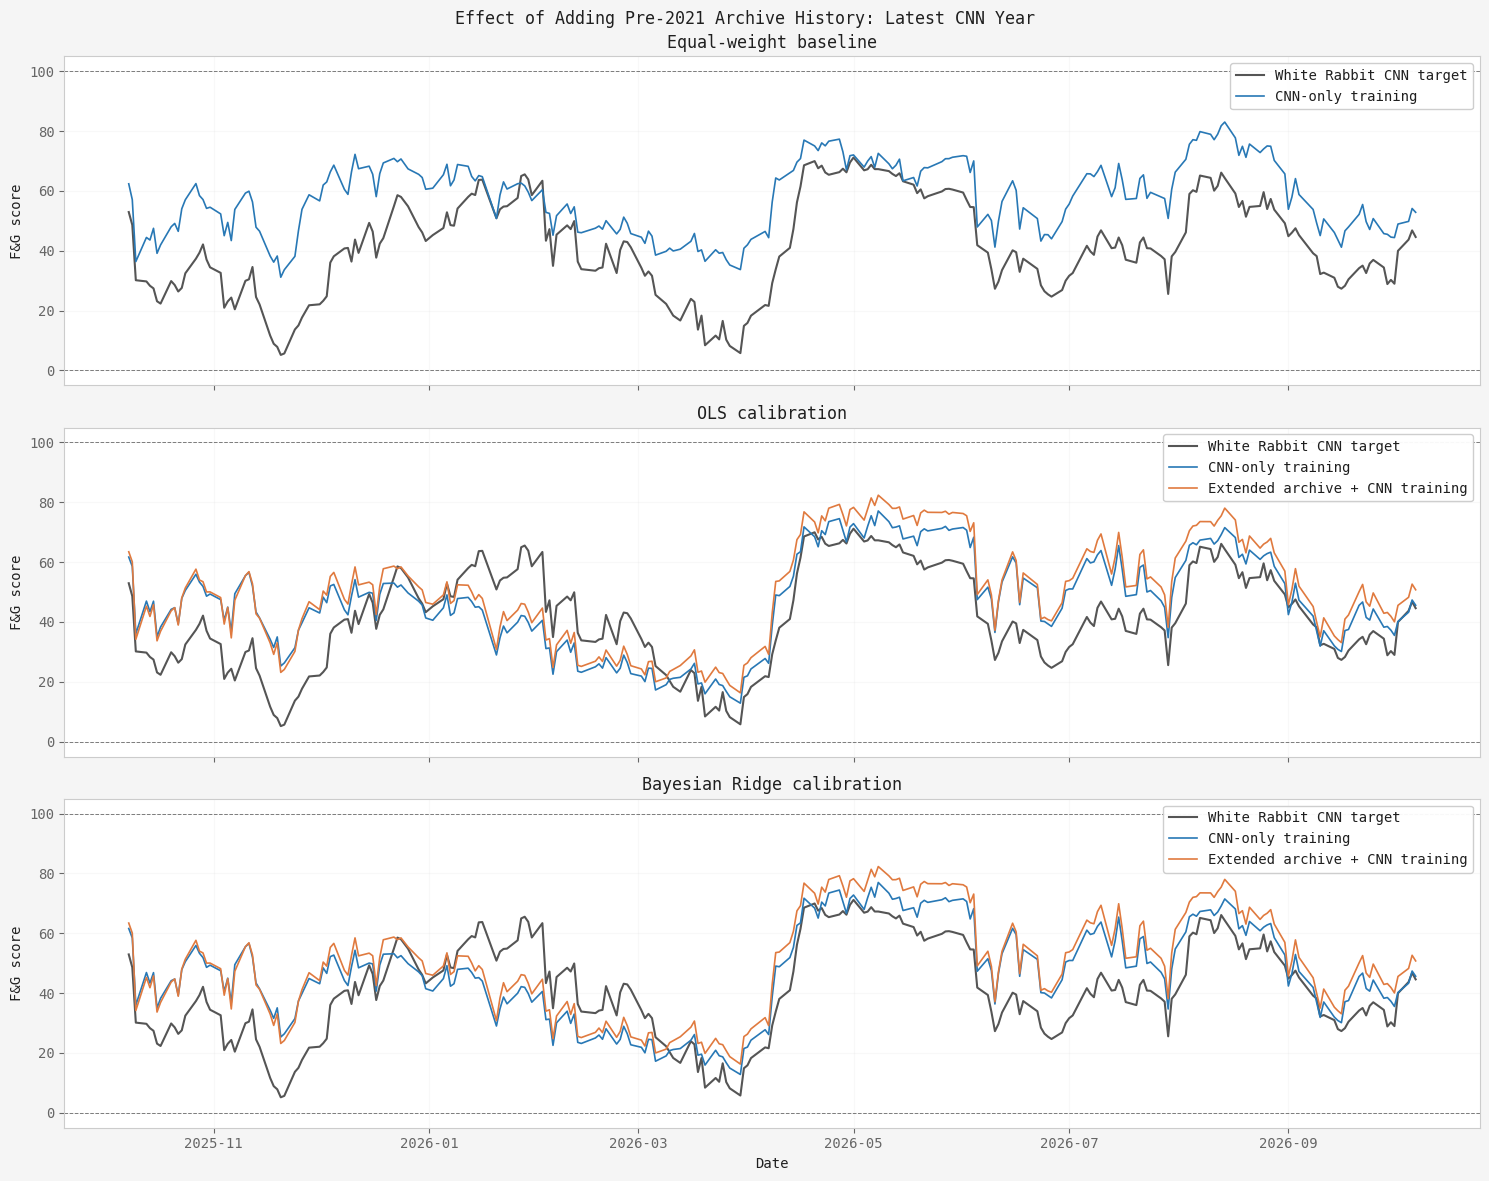

(<Figure size 1500x1200 with 3 Axes>,
 array([<Axes: title={'center': 'Equal-weight baseline'}, ylabel='F&G score'>,
        <Axes: title={'center': 'OLS calibration'}, ylabel='F&G score'>,
        <Axes: title={'center': 'Bayesian Ridge calibration'}, xlabel='Date', ylabel='F&G score'>],
       dtype=object))

In [17]:
from archive_sensitivity import plot_archive_sensitivity

# The figure has three panels: equal-weight baseline, OLS, and Bayesian Ridge.
# The regression panels compare CNN-only training with archive-plus-CNN training.
plot_archive_sensitivity(archive_predictions)


## 8. GRU Benchmark and Simple Mean Ensemble on Post-2021 CNN Data

This section tests whether a recurrent model can improve on Bayesian Ridge during the CNN-backed period. It uses the same latest calendar-year CNN test window as the archive sensitivity analysis above, with training restricted to earlier CNN-backed rows. That keeps the comparison directly comparable to the **CNN-only training** results in Section 7 and avoids mixing the third-party pre-2021 archive into this experiment.

The GRU receives a sequence: for each date, it uses the component scores from the preceding 20 trading observations, including that date, to estimate the CNN score. The network has two stacked GRU layers with 32 hidden units and dropout. A chronological validation tail selects the training duration; the selected epoch count is then used to refit on the full pre-test period. The latest test year is not used for model selection. See the [PyTorch GRU documentation](https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html).

The **Simple Mean Ensemble** combines the four date-level estimates—Equal-weight, OLS, Bayesian Ridge, and GRU—with fixed weights of 25% each. It is a transparent arithmetic average, not a separately trained model. All five candidates are scored on the same latest-year dates.

PyTorch is optional in the project dependencies. If it is missing from the notebook environment, install it with `%pip install torch` and restart the kernel before running this section. Treat GRU and ensemble as exploratory candidates: this latest-year comparison does not establish stability across market regimes. Compare MAE, RMSE, and R² on identical dates. Bayesian Ridge's 95% interval coverage is reported separately because the other candidates do not provide a comparable posterior predictive interval.

,model,n_train,train_start,train_end,test_start,test_end,n_test,MAE,RMSE,R2,coverage_95,gru_sequence_length,gru_best_epoch,gru_validation_best_loss,gru_final_train_loss
0,Equal-weight,NaN,None,None,2025-10-08,2026-10-07,250,16.388,18.387,-0.306,NaN,NaN,NaN,NaN,NaN
1,OLS,NaN,None,2025-10-07,2025-10-08,2026-10-07,250,10.668,12.598,0.387,NaN,NaN,NaN,NaN,NaN
2,Bayesian Ridge,1177.0,2021-02-01,2025-10-07,2025-10-08,2026-10-07,250,10.637,12.576,0.389,0.856,NaN,NaN,NaN,NaN
3,GRU,1158.0,2021-03-01,2025-10-07,2025-10-08,2026-10-07,250,8.793,10.385,0.583,NaN,20.0,119.0,29.89,14.471
4,Simple Mean Ensemble,NaN,None,2025-10-07,2025-10-08,2026-10-07,250,10.537,12.203,0.425,NaN,NaN,NaN,NaN,NaN


(<Figure size 1500x600 with 1 Axes>,
 <Axes: title={'center': 'CNN-only calibration: latest-year benchmark comparison'}, xlabel='Date', ylabel='Fear & Greed score'>)

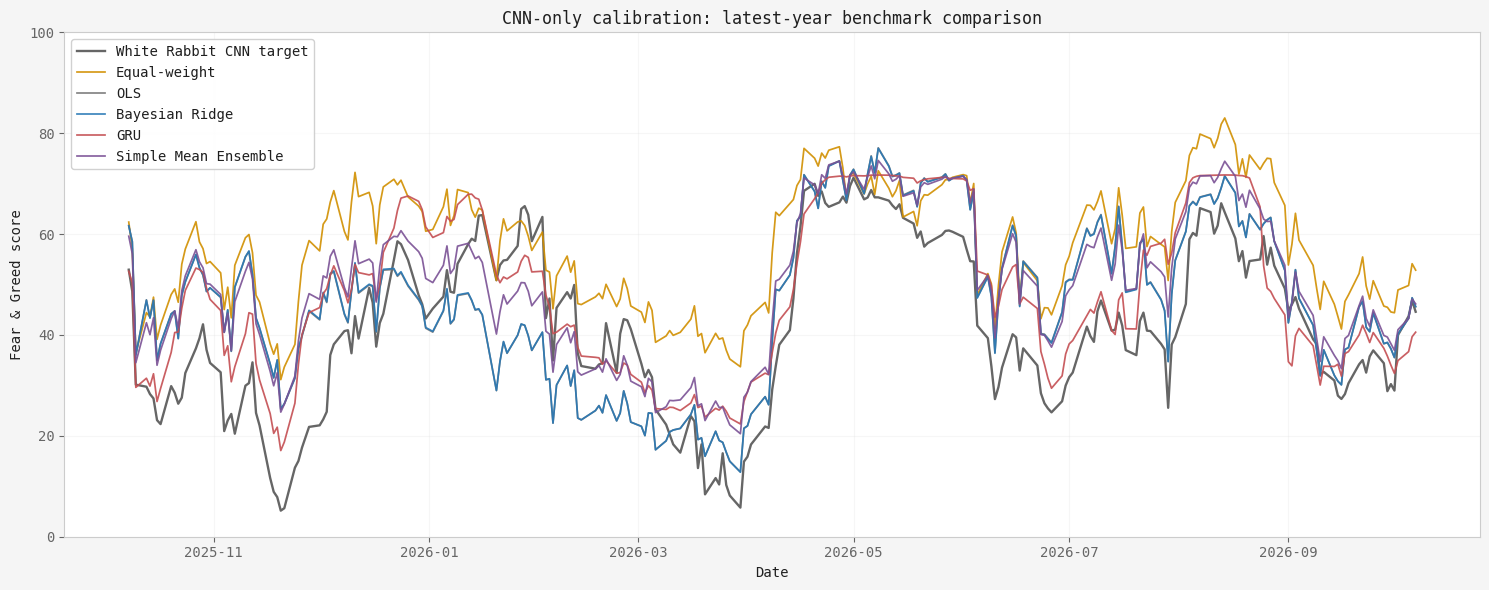

In [18]:
from gru_benchmark import compare_gru_with_bayesian, plot_gru_comparison

gru_comparison, gru_predictions = compare_gru_with_bayesian(
    history_frame=calibration_df,
    test_years=1,
    sequence_length=20,
    hidden_size=32,
    num_layers=2,
    dropout=0.1,
    max_epochs=250,
    patience=20,
    random_state=42,
)

display(gru_comparison.round(3))
plot_gru_comparison(gru_predictions)


### Probabilistic GRU comparison: Gaussian NLL and quantile loss

This comparison trains three same-day calibration GRUs: the base point model (MSE), a Gaussian model trained by negative log-likelihood that outputs mu and sigma, and a quantile model trained with pinball loss that outputs q10, q50, and q90. All three use the complete historical target sample available before the test window, including White Rabbit's pre-2021 third-party archive and the post-2021 CNN-backed observations. They are evaluated on the latest calendar year of CNN-backed observations, so the evaluation target remains the CNN series.

Sigma estimates uncertainty around mu; it is not fitted to equal the target. Review whether it is smaller on dates with smaller errors and whether its 90% interval has sensible coverage and width. The table also reports the archive/CNN training-row counts so the source mixture is explicit. This latest-year comparison is exploratory and has already been inspected elsewhere in the notebook.

Features used: ['score_momentum_spx', 'score_strength_proxy', 'score_breadth_rsp_spx', 'score_safe_haven_20d', 'score_junk_bond_mom_20d', 'score_hy_spread', 'score_vix_rel']
Features excluded (no CNN coverage): ['score_put_call']


,model,n_test,MAE,RMSE,R2,validation_objective,best_epoch,n_train,n_archive_train,n_cnn_train,NLL,interval_90_coverage,interval_90_mean_width,sigma_abs_error_spearman
0,GRU point (MSE),250,11.053,13.434,0.303,80.154,27,3691,2514,1177,NaN,NaN,NaN,NaN
1,GRU Gaussian NLL,250,11.169,13.352,0.311,3.959,26,3691,2514,1177,4.088,0.760,35.835,-0.091
2,GRU Quantile 10/50/90,250,10.885,12.857,0.361,2.582,21,3691,2514,1177,NaN,0.888,34.772,NaN


,model,n_train,n_archive_train,n_cnn_train
0,GRU point (MSE),3691,2514,1177
1,GRU Gaussian NLL,3691,2514,1177
2,GRU Quantile 10/50/90,3691,2514,1177


(<Figure size 1500x600 with 1 Axes>,
 <Axes: title={'center': 'Same-day CNN calibration: point and uncertainty-aware GRUs'}, xlabel='Date', ylabel='Fear & Greed score'>)

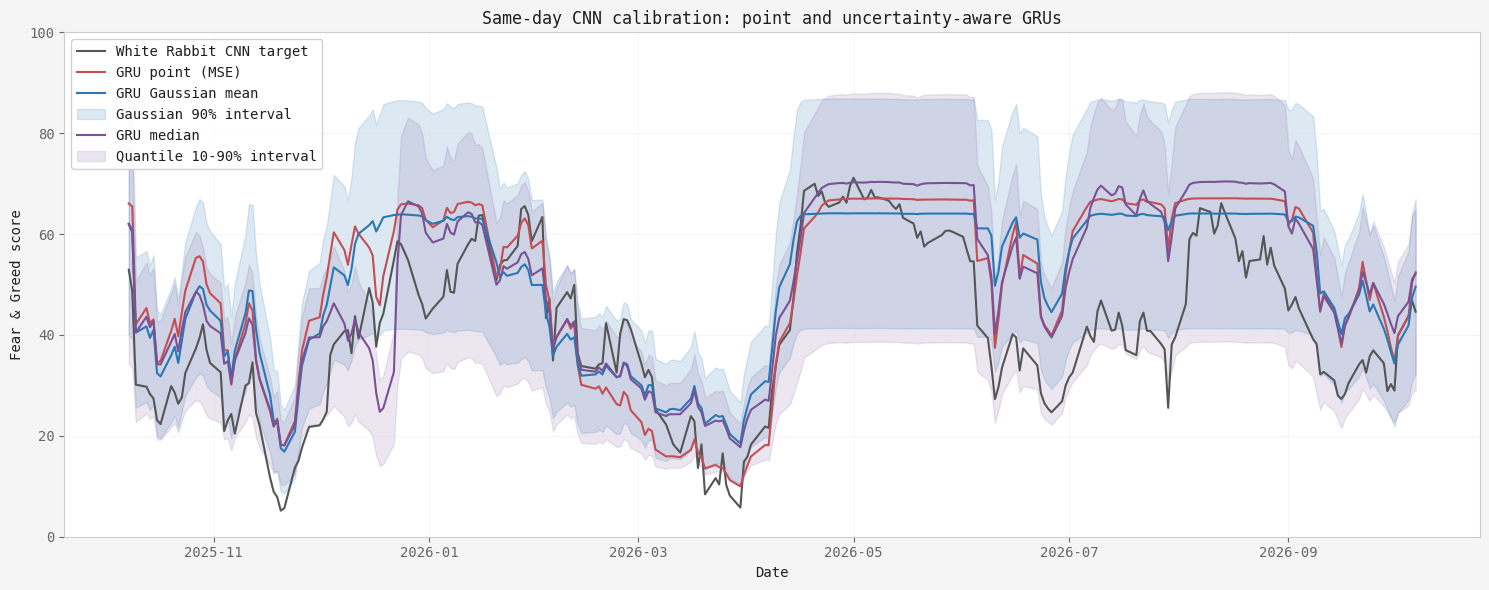

In [19]:
from gru_uncertainty import compare_probabilistic_grus, plot_probabilistic_grus

# Reuse the all-source history already loaded in the archive diagnostic.
all_history_for_gru = globals().get("combined_history")
if all_history_for_gru is None or not all_history_for_gru["source"].eq("third_party_archive").any():
    from load_calibration_data import load_calibration_data
    all_history_for_gru = load_calibration_data(
        start_date="2011-01-03",
        history_start="2005-01-01",
        source="all",
    )

probabilistic_metrics, probabilistic_predictions = compare_probabilistic_grus(
    history_frame=all_history_for_gru,
    test_years=1,
    sequence_length=20,
    hidden_size=32,
    num_layers=2,
    dropout=0.1,
    max_epochs=250,
    patience=20,
    random_state=42,
)

print("Features used:", probabilistic_metrics.attrs["feature_columns"])
print("Features excluded (no CNN coverage):", probabilistic_metrics.attrs["excluded_features_zero_cnn_coverage"])
display(probabilistic_metrics.round(3))
display(probabilistic_metrics[["model", "n_train", "n_archive_train", "n_cnn_train"]])
plot_probabilistic_grus(probabilistic_predictions)

### Common latest-year comparison

The table compares Equal-weight, OLS, Bayesian Ridge, GRU, and their fixed-weight Simple Mean Ensemble on the exact same latest-year dates. The ensemble prediction is the arithmetic mean of the four member predictions for each date; no weights are estimated from this test window. This is a retrospective comparison, not an independent future test. Read it together with the expanding-window results: GRU and the ensemble have only this latest-year evaluation, while the linear candidates also have development folds.

In [20]:
metric_cols = ["MAE", "RMSE", "R2", "n_test"]

benchmark_summary = (
    gru_comparison
    .set_index("model")[metric_cols]
    .rename(index={"GRU": "GRU point (CNN-only training)"})
)

probabilistic_summary = (
    probabilistic_metrics
    .set_index("model")[metric_cols]
)

latest_year_summary = (
    pd.concat([benchmark_summary, probabilistic_summary])
    .sort_values("RMSE")
)

display(latest_year_summary.round(3))

,MAE,RMSE,R2,n_test
model,,,,
GRU point (CNN-only training),8.793,10.385,0.583,250
Simple Mean Ensemble,10.537,12.203,0.425,250
Bayesian Ridge,10.637,12.576,0.389,250
OLS,10.668,12.598,0.387,250
GRU Quantile 10/50/90,10.885,12.857,0.361,250
GRU Gaussian NLL,11.169,13.352,0.311,250
GRU point (MSE),11.053,13.434,0.303,250
Equal-weight,16.388,18.387,-0.306,250


## 9. Save the Tested Calibrators for the Web Service

This cell only serializes fitted models; it does not train or refit anything. It selects the lowest-RMSE fitted GRU among the point, Gaussian-NLL, and quantile candidates on their common latest-CNN-year holdout. It saves that GRU with the already-tested post-2021 Bayesian Ridge model in one PyTorch checkpoint. The Bayesian checkpoint includes its scaler, posterior mean coefficients, and posterior covariance; the GRU includes its state dictionary, scaler, architecture, objective, feature order, and training-source counts.

The current benchmark functions discarded their fitted weights, so rerun only the all-history three-GRU comparison cell once after reloading its module; it now retains their state dictionaries. For Bayesian Ridge, this cell reuses the fitted `final_candidate` from the holdout section if the newer benchmark did not retain it. Then run this save-only cell. No other notebook cells need to be rerun.

In [23]:
from calibration_artifacts import (
    bayesian_checkpoint_from_pipeline,
    save_calibration_artifacts,
)

bayesian_checkpoint = gru_comparison.attrs.get("bayesian_checkpoint")
if bayesian_checkpoint is None:
    bayesian_checkpoint = bayesian_checkpoint_from_pipeline(
        final_candidate,
        feature_columns=feature_cols,
        train_start=development_sample.index.min().strftime("%Y-%m-%d"),
        train_end=development_sample.index.max().strftime("%Y-%m-%d"),
        test_start=final_holdout.index.min().strftime("%Y-%m-%d"),
        test_end=final_holdout.index.max().strftime("%Y-%m-%d"),
    )

display(pd.Series(bayesian_checkpoint, name="saved value"))

calibration_artifact_paths = save_calibration_artifacts(
    bayesian_checkpoint=bayesian_checkpoint,
    gru_metrics=probabilistic_metrics,
    output_path="models/calibration/fg_calibrators.pt",
)
display(pd.Series(calibration_artifact_paths, name="saved value"))

feature_columns         [score_momentum_spx, score_strength_proxy, sco...
scaler_mean             [50.67173740070936, 51.289530822241105, 46.743...
scaler_scale            [29.138147226218837, 29.33870053443438, 31.994...
coef                    [16.691454312687494, -8.141801805376836, 0.138...
intercept                                                       48.471699
posterior_covariance    [[0.5834985615012552, -0.5214749410155137, 0.0...
alpha                                                            0.010818
lambda                                                            0.01677
train_start                                                    2021-02-01
train_end                                                      2025-10-07
test_start                                                     2025-10-08
test_end                                                       2026-10-07
target_source                                                cnn_endpoint
Name: saved value, dtype: object

checkpoint          models\calibration\fg_calibrators.pt
selected_gru                       GRU Quantile 10/50/90
selection_metric                                    RMSE
Name: saved value, dtype: object

## 10. Conclusion and Next Steps



Write the conclusion after reviewing the results. Report metric-specific rankings: the lowest mean fold RMSE is only the result under the predeclared RMSE rule, and the saved run shows that MAE/R² may rank candidates differently. Compare all linear candidates on the row-based holdout and all five candidates on the common latest-year window. The latest year has already been inspected, so do not call it an untouched test.

Treat GRU and its fixed-weight ensemble as candidates, not proven winners, until their stability has been reviewed across comparable chronological folds. The artifact cell refits Bayesian Ridge on post-2021 CNN data and the selected GRU on combined archive-plus-CNN history; those refitted weights do not carry the validation performance claim.

Next, use the separate weekly forecasting notebook to compare last-value, mean, and median weekly targets and the six-week forecast candidates. Keep forecast metrics separate from same-day calibration results, preserve the exact data snapshot and model metadata, and document that the current web service needs inference adapters before it can expose OLS, GRU, or the ensemble.

In [22]:
# Compact results block: keep the RMSE rule and metric disagreement visible.
print(f"Lowest mean fold-RMSE candidate: {selected_model}")
print("Development-fold summary:")
display(cv_summary.round(3))
print("All linear candidates on the row-based holdout:")
display(holdout_results.round(3))
print("Equal-weight, OLS, Bayesian Ridge, GRU, and their simple mean on the common latest-year window:")
display(latest_year_summary.round(3))

Lowest mean fold-RMSE candidate: Equal-weight
Development-fold summary:


,mean_MAE,sd_MAE,mean_RMSE,sd_RMSE,mean_R2,mean_coverage_95
model,,,,,,
Bayesian Ridge,9.649,2.700,11.541,2.937,0.426,0.914
Equal-weight,9.286,2.924,10.741,3.127,0.393,NaN
OLS,9.728,2.690,11.666,2.929,0.415,NaN


All linear candidates on the row-based holdout:


,n,MAE,RMSE,R2,coverage_95
model,,,,,
Equal-weight,252,16.330,18.332,-0.303,NaN
OLS,252,10.686,12.602,0.384,NaN
Bayesian Ridge,252,10.654,12.579,0.386,0.853


Equal-weight, OLS, Bayesian Ridge, GRU, and their simple mean on the common latest-year window:


,MAE,RMSE,R2,n_test
model,,,,
GRU point (CNN-only training),8.793,10.385,0.583,250
Simple Mean Ensemble,10.537,12.203,0.425,250
Bayesian Ridge,10.637,12.576,0.389,250
OLS,10.668,12.598,0.387,250
GRU Quantile 10/50/90,10.885,12.857,0.361,250
GRU Gaussian NLL,11.169,13.352,0.311,250
GRU point (MSE),11.053,13.434,0.303,250
Equal-weight,16.388,18.387,-0.306,250
